In [28]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision import transforms
from torchvision.datasets import MNIST
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
def linear_beta_schedule(timesteps):
    """
    Cronograma linear de beta: controla quanto ruido eh adicionado em cada passo de tempo

    """
    beta_start = 0.0001
    beta_end = 0.02
    return torch.linspace(beta_start, beta_end, timesteps)


# qtde de passos
T = 200

betas = linear_beta_schedule(T)
alphas = 1.0 - betas
alphas_cumprod = torch.cumprod(alphas, axis=0)


# processo de de difusao direta
def forward_diffusion_sample(x_0, t, noise=None):
    """
    Adicionar ruido na imagem x_0 ate um passo t, usando a formula direta (sem iteracoes)
    """
    if noise is None:
        # rand_like eh uma funcao que retorna uma matriz com o mesmo shape de x_0, mas com valores amostrados de uma distribuicao gaussiana
        noise = torch.randn_like(x_0)
    # alphas_cumprod fica na CPU; move para o mesmo device de t antes de indexar
    alphas_cumprod_t = alphas_cumprod.to(t.device)[t]
    sqrt_alphas_cumprod = torch.sqrt(alphas_cumprod_t)[:, None, None, None]
    sqrt_one_minus_alphas_cumprod = torch.sqrt(1 - alphas_cumprod_t)[
        :, None, None, None
    ]
    return sqrt_alphas_cumprod * x_0 + sqrt_one_minus_alphas_cumprod * noise, noise


# rede neural simples que recebe uma imagem ruidosa como entrada e preve o ruido
class SimpleModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            # lembre: nn.Conv2d(in_channels, out_channels, kernel_size)
            nn.Conv2d(1, 32, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 32, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 1, 3, padding=1),
        )

    def forward(self, x, t):
        return self.net(x)


# carrega o conjunto de dados MNIST
def get_data():
    transform = transforms.Compose([
        transforms.ToTensor(),
        # aplica normalizacao para o intervalo [-1,1]
        lambda x: x * 2 - 1
    ])
    try:
        # usa o MNIST da pasta local, se ja estiver baixado
        dataset = MNIST(root="./data", train=True, download=False, transform=transform)
    except RuntimeError:
        # nao encontrado localmente: baixa o conjunto de dados
        dataset = MNIST(root="./data", train=True, download=True, transform=transform)

    # data loader com batch size de 128
    dataloader = DataLoader(dataset, batch_size=128, shuffle=True)
    return dataloader

# treino do modelo
def train(model, dataloader, optimizer, device, epochs=5):
    for epoch in range(epochs):
        for step, (x, _) in enumerate(dataloader):
            x = x.to(device)

            # sorteia ate qual passo t vai ser aplicado o ruido (t = 0..T-1)
            t = torch.randint(0, T, (x.shape[0],), device=device).long()

            # DIFUSAO DIRETA: imagem pura -> ruido 
            # NOTE: a difusao direta retorna o nosso rotulo: o ruido
            x_noisy, noise = forward_diffusion_sample(x, t)

            # a rede tenta prever o ruido aplicado em x: minimizamos a perda MSE entre o ruido
            # real (da cadeia de Markov) e o previsto
            noise_pred = model(x_noisy, t)
            loss = F.mse_loss(noise_pred, noise)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        print(f"Epoch {epoch}: Loss {loss.item():.4f}")

# validacao do modelo: amostragem
# NOTE: esta etapa gera nova imagens partindo de ruido aleatorio e removendo-o gradualmente com o modelo treinado
@torch.no_grad()
def sample(model, image_size, num_samples):

    # coloque o modelo em modo de avaliacao (inferencia)
    model.eval()

    # gera ruido puro
    x = torch.randn((num_samples, 1, image_size, image_size), device=device)

    # DIFUSAO REVERSA: ruido puro -> imagem
    for t in reversed(range(T)):
        t_tensor = torch.full((num_samples,), t, device=device, dtype=torch.long)
        pred_noise = model(x, t_tensor)
        alpha = alphas[t]
        alpha_bar = alphas_cumprod[t]
        beta = betas[t]
        if t > 0:
            # injetamos um pouco de ruido novo (sqrt(beta_t) * z)
            noise = torch.randn_like(x)
        else:
            noise = 0
        # usamos o ruido inferido pelo modelo para refazer a imagem
        x = (1 / torch.sqrt(alpha)) * (x - (beta / torch.sqrt(1 - alpha_bar)) * pred_noise) + torch.sqrt(beta) * noise
    return x

using: cuda


100%|██████████| 9.91M/9.91M [00:01<00:00, 9.66MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 321kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 2.99MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 16.6MB/s]


Epoch 0: Loss 0.1357
Epoch 1: Loss 0.1179
Epoch 2: Loss 0.1275
Epoch 3: Loss 0.1133
Epoch 4: Loss 0.1250


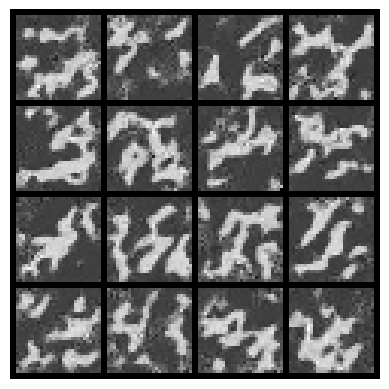

In [30]:
# treinando o modelo
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"using: {device}")
model = SimpleModel().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
dataloader = get_data()
train(model, dataloader, optimizer, device)

# gere 16 amostras 28x28
samples = sample(model, 28, 16)

grid = torchvision.utils.make_grid(samples.cpu(), nrow=4, normalize=True)

# visualizacao dos resultados
plt.imshow(grid.permute(1, 2, 0))
plt.axis("off")
plt.show()